In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/__results__.html
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/__huggingface_repos__.json
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/__notebook__.ipynb
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/__output__.json
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/custom.css
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/separationllm-qwen3-1.7b-lora/README.md
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/separationllm-qwen3-1.7b-lora/checkpoint-603/adapter_model.safetensors
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/separationllm-qwen3-1.7b-lora/checkpoint-603/trainer_state.json
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/separationllm-qwen3-1.7b-lora/checkpoint-603/training_args.bin
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/separationllm-qwen3-1.7b-lora/checkpoint-603/adapter_config.json
/kaggle

In [2]:
%env CUDA_VISIBLE_DEVICES=0

%pip uninstall -y torchao

%pip install -q \
    transformers==5.16.1 \
    peft==0.20.0 \
    datasets \
    accelerate \
    scikit-learn

env: CUDA_VISIBLE_DEVICES=0
Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [3]:
import re, numpy as np, torch
from collections import Counter
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel
from datasets import load_dataset
from sklearn.metrics import accuracy_score, confusion_matrix

MODEL_NAME = "Qwen/Qwen3-1.7B"
ADAPTER_PATH = "/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/separationllm-qwen3-1.7b-lora-final"
DATA_DIR = "/kaggle/input/datasets/yeonjiji/separation-data"
DEVICE = "cuda"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
base = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float16, device_map="cuda")
ft_model = PeftModel.from_pretrained(base, ADAPTER_PATH).eval()
test_dataset = load_dataset("json", data_files=f"{DATA_DIR}/test.jsonl", split="train")

LABELS = ["VL", "L", "U", "M", "H"]
label_ids = [tokenizer.encode(l, add_special_tokens=False)[0] for l in LABELS]

def predict_label(messages, use_base=False):
    # Prediction = the label (of the 5) with the highest next-token logit
    prompt = tokenizer.apply_chat_template(messages, tokenize=False,
                                           add_generation_prompt=True, enable_thinking=False)
    inputs = tokenizer(prompt, return_tensors="pt", add_special_tokens=False).to(DEVICE)
    ctx = ft_model.disable_adapter() if use_base else torch.no_grad()
    with ctx, torch.no_grad():
        logits = ft_model(**inputs, use_cache=False).logits[0, -1]
    return LABELS[int(torch.argmax(logits[label_ids]))]

y_true = np.array([ex["messages"][-1]["content"].strip() for ex in test_dataset])
y_ft   = np.array([predict_label(ex["messages"][:-1])                for ex in tqdm(test_dataset)])
y_base = np.array([predict_label(ex["messages"][:-1], use_base=True) for ex in tqdm(test_dataset)])

maj = Counter(y_true).most_common(1)[0]
print(f"Majority-class baseline ({maj[0]}): {maj[1] / len(y_true):.3f}")
print(f"Base accuracy:       {accuracy_score(y_true, y_base):.3f}")
print(f"Fine-tuned accuracy: {accuracy_score(y_true, y_ft):.3f}")
print("\nBase prediction counts:", Counter(y_base))
print(confusion_matrix(y_true, y_base, labels=LABELS))

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

  0%|          | 0/501 [00:00<?, ?it/s]

  0%|          | 0/501 [00:00<?, ?it/s]

Majority-class baseline (U): 0.345
Base accuracy:       0.114
Fine-tuned accuracy: 0.591

Base prediction counts: Counter({np.str_('VL'): 481, np.str_('M'): 20})
[[ 52   0   0   0   0]
 [122   0   0   3   0]
 [161   0   0  12   0]
 [104   0   0   5   0]
 [ 42   0   0   0   0]]


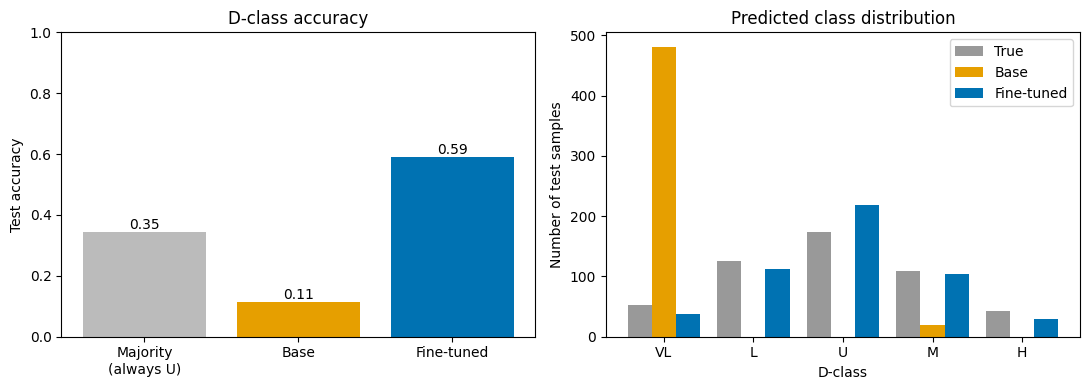

In [4]:
import matplotlib.pyplot as plt

acc = {
    "Majority\n(always " + maj[0] + ")": maj[1] / len(y_true),
    "Base":       accuracy_score(y_true, y_base),
    "Fine-tuned": accuracy_score(y_true, y_ft),
}

# How often each class is predicted (vs. how often it is the true answer)
count = lambda arr: [int((arr == l).sum()) for l in LABELS]
dist = {"True": count(y_true), "Base": count(y_base), "Fine-tuned": count(y_ft)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Left: overall accuracy
bars = ax1.bar(acc.keys(), acc.values(), color=["#bbbbbb", "#e69f00", "#0072b2"])
ax1.bar_label(bars, fmt="%.2f")
ax1.set_ylim(0, 1)
ax1.set_ylabel("Test accuracy")
ax1.set_title("D-class accuracy")

# Right: which classes each model predicts
x = np.arange(len(LABELS))
w = 0.27
for i, (name, c) in enumerate(dist.items()):
    ax2.bar(x + (i - 1) * w, c, w, label=name,
            color=["#999999", "#e69f00", "#0072b2"][i])
ax2.set_xticks(x, LABELS)
ax2.set_xlabel("D-class")
ax2.set_ylabel("Number of test samples")
ax2.set_title("Predicted class distribution")
ax2.legend()

plt.tight_layout()
plt.savefig("/kaggle/working/base_vs_ft_accuracy.png", dpi=200)
plt.show()